In [1]:
%pip install --force-reinstall "numpy==2.2.6" "scipy==1.15.3" "nltk==3.9.2" "pandas==2.2.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 40.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 36.6 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 59.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 57.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 29.7 MB/s  0:00:00
  Attempting uninstall: pytz
    Found existing installation: pytz 2025.2
    Uninstalling pytz-2025.2:
      Successfully uninstalled pytz-2025.2
  Attempting uninstall: tzdata
    Found existing installation: tzdata 2026.5
    Uninstalling tzdata-2026.5:
      Successfully uninstalled tzdata-2026.5
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: six
    Found existing installation: six 1.17.0
    Uninstalling six-1.17.0:
      Successfully uninstalled six-1.17.0
  Attempting uninstall: rege

In [1]:
import numpy as np
import scipy
import pandas as pd
import nltk

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("NLTK:", nltk.__version__)

print("All imports successful!")

NumPy: 2.2.6
SciPy: 1.15.3
Pandas: 2.2.3
NLTK: 3.9.2
All imports successful!


In [2]:

# Cell 2: Download the dataset

import nltk
nltk.download("movie_reviews")

from nltk.corpus import movie_reviews

print("Dataset downloaded successfully!")
print("Total reviews:", len(movie_reviews.fileids()))


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Dataset downloaded successfully!
Total reviews: 2000


In [3]:

# Cell 3: Create a dataset table

reviews = []

for file_id in movie_reviews.fileids():
    review_text = movie_reviews.raw(file_id)
    sentiment = movie_reviews.categories(file_id)[0]

    reviews.append({
        "review": review_text,
        "sentiment": sentiment
    })

df = pd.DataFrame(reviews)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nSentiment counts:")
print(df["sentiment"].value_counts())


                                              review sentiment
0  plot : two teen couples go to a church party ,...       neg
1  the happy bastard's quick movie review \ndamn ...       neg
2  it is movies like these that make a jaded movi...       neg
3   " quest for camelot " is warner bros . ' firs...       neg
4  synopsis : a mentally unstable man undergoing ...       neg

Dataset shape: (2000, 2)

Sentiment counts:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


In [4]:

# Cell 4: Explore our dataset

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate reviews:")
print(df.duplicated().sum())

print("\nOne positive review:")
print(df[df["sentiment"] == "pos"]["review"].iloc[0])

print("\nOne negative review:")
print(df[df["sentiment"] == "neg"]["review"].iloc[0])


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     2000 non-null   object
 1   sentiment  2000 non-null   object
dtypes: object(2)
memory usage: 31.4+ KB

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate reviews:
0

One positive review:
films adapted from comic books have had plenty of success , whether they're about superheroes ( batman , superman , spawn ) , or geared toward kids ( casper ) or the arthouse crowd ( ghost world ) , but there's never really been a comic book like from hell before . 
for starters , it was created by alan moore ( and eddie campbell ) , who brought the medium to a whole new level in the mid '80s with a 12-part series called the watchmen . 
to say moore and campbell thoroughly researched the subject of jack the ripper would be like saying michael jackson is starting to 

In [5]:

import re

def clean_text(text):
    text = text.lower()                   # Convert to lowercase
    text = re.sub(r"<.*?>", " ", text)     # Remove HTML tags
    text = re.sub(r"[^a-z\s]", " ", text)  # Keep letters and spaces
    text = re.sub(r"\s+", " ", text)       # Remove extra spaces
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

print("Original review:")
print(df["review"].iloc[0][:300])

print("\nCleaned review:")
print(df["clean_review"].iloc[0][:300])


Original review:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the

Cleaned review:
plot two teen couples go to a church party drink and then drive they get into an accident one of the guys dies but his girlfriend continues to see him in her life and has nightmares what s the deal watch the movie and sorta find out critique a mind fuck movie for the teen generation that touches on 


In [6]:

print(df[["review", "clean_review", "sentiment"]].head())
print("\nDataset shape:", df.shape)


                                              review  \
0  plot : two teen couples go to a church party ,...   
1  the happy bastard's quick movie review \ndamn ...   
2  it is movies like these that make a jaded movi...   
3   " quest for camelot " is warner bros . ' firs...   
4  synopsis : a mentally unstable man undergoing ...   

                                        clean_review sentiment  
0  plot two teen couples go to a church party dri...       neg  
1  the happy bastard s quick movie review damn th...       neg  
2  it is movies like these that make a jaded movi...       neg  
3  quest for camelot is warner bros first feature...       neg  
4  synopsis a mentally unstable man undergoing ps...       neg  

Dataset shape: (2000, 3)


In [7]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical features
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_review"])
y = df["sentiment"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Feature matrix shape: (2000, 5000)
Target shape: (2000,)


In [8]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1600
Testing samples: 400


In [9]:

# Cell 8: Train the model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [10]:

from sklearn.metrics import accuracy_score, classification_report

# Predict sentiments for unseen test reviews
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 83.0 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.85      0.80      0.82       200
         pos       0.81      0.86      0.84       200

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



In [11]:

# Cell 11: Predict sentiment for new reviews

def predict_sentiment(text):
    cleaned_text = clean_text(text)
    text_vector = tfidf.transform([cleaned_text])
    prediction = model.predict(text_vector)[0]

    return prediction.upper()

print(predict_sentiment("This movie was amazing and wonderful!"))
print(predict_sentiment("This movie was boring and terrible!"))
print(predict_sentiment("I enjoyed every moment of this film."))
print(predict_sentiment("The story was dull and disappointing."))


POS
NEG
NEG
NEG


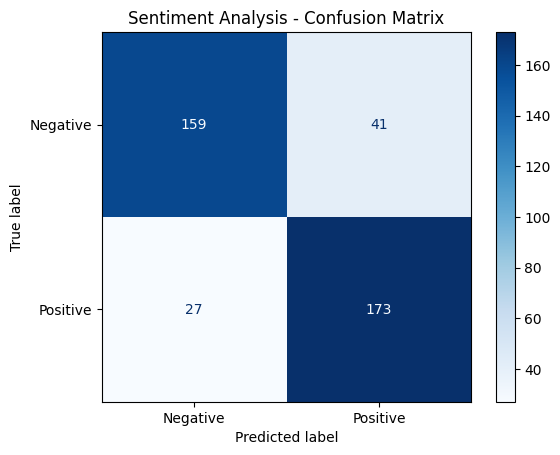

In [12]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=["neg", "pos"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues")
plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()


In [13]:

import gradio as gr

def analyze_review(text):
    if not text.strip():
        return "Please enter a movie review."

    cleaned_text = clean_text(text)
    text_vector = tfidf.transform([cleaned_text])
    prediction = model.predict(text_vector)[0]

    if prediction == "pos":
        return "Positive Sentiment 😊"
    else:
        return "Negative Sentiment ☹️"

app = gr.Interface(
    fn=analyze_review,
    inputs=gr.Textbox(
        lines=4,
        label="Enter a movie review",
        placeholder="Type your review here..."
    ),
    outputs=gr.Textbox(label="Predicted Sentiment"),
    title="AI Movie Review Sentiment Analyzer",
    description="Enter an English movie review to predict its sentiment."
)

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8cb7d69feadc7bb3d7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:

test_words = ["good", "GOOD", "good movie", "excellent movie",
              "bad movie", "amazing"]

for text in test_words:
    cleaned = clean_text(text)
    vector = tfidf.transform([cleaned])
    prediction = model.predict(vector)[0]
    print(f"{text:20} -> {prediction}")


good                 -> neg
GOOD                 -> neg
good movie           -> neg
excellent movie      -> pos
bad movie            -> neg
amazing              -> pos


In [15]:

word = "good"
word_vector = tfidf.transform([clean_text(word)])

print("Cleaned text:", clean_text(word))
print("Number of non-zero features:", word_vector.nnz)
print("Is 'good' in vocabulary:", "good" in tfidf.vocabulary_)


Cleaned text: good
Number of non-zero features: 1
Is 'good' in vocabulary: True


In [16]:

text = "GOOD"

cleaned = clean_text(text)
vector = tfidf.transform([cleaned])

print("Prediction:", model.predict(vector)[0])

probabilities = model.predict_proba(vector)[0]

for label, probability in zip(model.classes_, probabilities):
    print(f"{label}: {probability:.2%}")


Prediction: neg
neg: 50.22%
pos: 49.78%


In [17]:

def analyze_review(text):
    if not text.strip():
        return "Please enter a movie review."

    cleaned_text = clean_text(text)
    text_vector = tfidf.transform([cleaned_text])

    # Check whether the input contains any known features
    if text_vector.nnz == 0:
        return "Unable to analyze: no known words found."

    probabilities = model.predict_proba(text_vector)[0]
    class_probabilities = dict(zip(model.classes_, probabilities))

    neg_prob = class_probabilities["neg"]
    pos_prob = class_probabilities["pos"]

    # Flag predictions when the model is uncertain
    if abs(pos_prob - neg_prob) < 0.10:
        return (
            f"Neutral / Uncertain 😐\n"
            f"Negative: {neg_prob:.2%} | Positive: {pos_prob:.2%}"
        )

    if pos_prob > neg_prob:
        return f"Positive Sentiment 😊 (Score: {pos_prob:.2%})"

    return f"Negative Sentiment ☹️ (Score: {neg_prob:.2%})"


In [18]:
print(analyze_review("GOOD"))
print(analyze_review("This movie is absolutely wonderful and amazing"))
print(analyze_review("This movie is terrible and boring"))

Neutral / Uncertain 😐
Negative: 50.22% | Positive: 49.78%
Positive Sentiment 😊 (Score: 57.45%)
Negative Sentiment ☹️ (Score: 81.21%)


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Split the raw text before fitting TF-IDF
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

# Build an improved model pipeline
improved_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=2.0,
        max_iter=1000
    ))
])

# Train the model
improved_model.fit(X_train_text, y_train)

# Evaluate on unseen test reviews
improved_pred = improved_model.predict(X_test_text)

print("Improved Model Accuracy:",
      round(accuracy_score(y_test, improved_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, improved_pred))


Improved Model Accuracy: 88.0 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.87      0.89      0.88       200
         pos       0.89      0.87      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [20]:

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(C=1.0, random_state=42))
])

svm_model.fit(X_train_text, y_train)

svm_pred = svm_model.predict(X_test_text)

print("Linear SVM Accuracy:",
      round(accuracy_score(y_test, svm_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))


Linear SVM Accuracy: 88.0 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.89      0.86      0.88       200
         pos       0.87      0.90      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [21]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Original Logistic Regression",
              "Improved Logistic Regression",
              "Linear SVM"],
    "Accuracy (%)": [83.0, 88.0, 88.0],
    "Macro F1 (%)": [
        83.0,
        f1_score(y_test, improved_pred, average="macro") * 100,
        f1_score(y_test, svm_pred, average="macro") * 100
    ]
})

print(comparison.round(2).to_string(index=False))


                       Model  Accuracy (%)  Macro F1 (%)
Original Logistic Regression          83.0          83.0
Improved Logistic Regression          88.0          88.0
                  Linear SVM          88.0          88.0


In [22]:

test_reviews = [
    "GOOD",
    "This movie is good",
    "This movie is not good",
    "This movie is not bad",
    "This movie is amazing",
    "This movie is boring and terrible",
    "I expected better, but I hated it",
    "I thought I would hate it, but I loved it"
]

for review in test_reviews:
    prediction = improved_model.predict([review])[0]
    print(f"Review: {review}")
    print(f"Predicted sentiment: {prediction.upper()}")
    print("-" * 50)


Review: GOOD
Predicted sentiment: POS
--------------------------------------------------
Review: This movie is good
Predicted sentiment: NEG
--------------------------------------------------
Review: This movie is not good
Predicted sentiment: NEG
--------------------------------------------------
Review: This movie is not bad
Predicted sentiment: NEG
--------------------------------------------------
Review: This movie is amazing
Predicted sentiment: NEG
--------------------------------------------------
Review: This movie is boring and terrible
Predicted sentiment: NEG
--------------------------------------------------
Review: I expected better, but I hated it
Predicted sentiment: NEG
--------------------------------------------------
Review: I thought I would hate it, but I loved it
Predicted sentiment: POS
--------------------------------------------------


In [23]:

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

word_char_features = FeatureUnion([
    ("word", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        max_features=10000,
        min_df=2,
        sublinear_tf=True
    )),
    ("char", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=10000,
        min_df=2,
        sublinear_tf=True
    ))
])

advanced_model = Pipeline([
    ("features", word_char_features),
    ("classifier", LogisticRegression(
        C=2.0,
        max_iter=1000
    ))
])

advanced_model.fit(X_train_text, y_train)

advanced_pred = advanced_model.predict(X_test_text)

print("Advanced Model Accuracy:",
      round(accuracy_score(y_test, advanced_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, advanced_pred))


Advanced Model Accuracy: 87.75 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.89      0.86      0.88       200
         pos       0.87      0.89      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [24]:

test_reviews = [
    "This movie is amazing",
    "This movie is good",
    "This movie is not good",
    "This movie is not bad",
    "The movie was boring and terrible",
    "I hated it",
    "I expected to hate it, but I loved it"
]

for review in test_reviews:
    prediction = advanced_model.predict([review])[0]
    print(f"Review: {review}")
    print(f"Predicted sentiment: {prediction.upper()}")
    print("-" * 40)


Review: This movie is amazing
Predicted sentiment: NEG
----------------------------------------
Review: This movie is good
Predicted sentiment: NEG
----------------------------------------
Review: This movie is not good
Predicted sentiment: NEG
----------------------------------------
Review: This movie is not bad
Predicted sentiment: NEG
----------------------------------------
Review: The movie was boring and terrible
Predicted sentiment: NEG
----------------------------------------
Review: I hated it
Predicted sentiment: NEG
----------------------------------------
Review: I expected to hate it, but I loved it
Predicted sentiment: NEG
----------------------------------------


In [25]:

test_reviews = [
    "This movie is amazing",
    "This movie is good",
    "This movie is not good",
    "This movie is not bad",
    "The movie was boring and terrible",
    "I hated it",
    "I expected to hate it, but I loved it"
]

for review in test_reviews:
    improved_prediction = improved_model.predict([review])[0]
    advanced_prediction = advanced_model.predict([review])[0]

    print("Review:", review)
    print("Improved Model:", improved_prediction.upper())
    print("Advanced Model:", advanced_prediction.upper())
    print("-" * 50)


Review: This movie is amazing
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: This movie is good
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: This movie is not good
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: This movie is not bad
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: The movie was boring and terrible
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: I hated it
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------
Review: I expected to hate it, but I loved it
Improved Model: NEG
Advanced Model: NEG
--------------------------------------------------


In [26]:

# Check sentiment labels in our dataset
print(df["sentiment"].value_counts())

# Examine actual positive reviews
positive_reviews = df[df["sentiment"] == "pos"]["clean_review"]

print("\nSample positive reviews:\n")
for review in positive_reviews.head(5):
    print(review[:300])
    print("-" * 50)


sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Sample positive reviews:

films adapted from comic books have had plenty of success whether they re about superheroes batman superman spawn or geared toward kids casper or the arthouse crowd ghost world but there s never really been a comic book like from hell before for starters it was created by alan moore and eddie campbe
--------------------------------------------------
every now and then a movie comes along from a suspect studio with every indication that it will be a stinker and to everybody s surprise perhaps even the studio the film becomes a critical darling mtv films election a high school comedy starring matthew broderick and reese witherspoon is a current e
--------------------------------------------------
you ve got mail works alot better than it deserves to in order to make the film a success all they had to do was cast two extremely popular and attractive stars have them share the screen for about two hours a

In [27]:

test_reviews = [
    "This movie is amazing",
    "This movie is good",
    "This movie is not good",
    "This movie is not bad",
    "The movie was boring and terrible",
    "I hated it",
    "I expected to hate it, but I loved it"
]

for review in test_reviews:
    probabilities = improved_model.predict_proba([review])[0]
    classes = improved_model.classes_

    print("\nReview:", review)

    for label, probability in zip(classes, probabilities):
        print(f"{label.upper()}: {probability:.2%}")



Review: This movie is amazing
NEG: 54.71%
POS: 45.29%

Review: This movie is good
NEG: 53.35%
POS: 46.65%

Review: This movie is not good
NEG: 60.22%
POS: 39.78%

Review: This movie is not bad
NEG: 77.60%
POS: 22.40%

Review: The movie was boring and terrible
NEG: 88.11%
POS: 11.89%

Review: I hated it
NEG: 53.93%
POS: 46.07%

Review: I expected to hate it, but I loved it
NEG: 55.36%
POS: 44.64%


In [28]:

# Check words in positive and negative training reviews
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

positive_text = " ".join(
    df[df["sentiment"] == "pos"]["clean_review"]
)

negative_text = " ".join(
    df[df["sentiment"] == "neg"]["clean_review"]
)

vectorizer = CountVectorizer(stop_words="english")
positive_counts = vectorizer.fit_transform([positive_text])
negative_counts = vectorizer.transform([negative_text])

words = vectorizer.get_feature_names_out()

word_comparison = pd.DataFrame({
    "word": words,
    "positive_count": positive_counts.toarray()[0],
    "negative_count": negative_counts.toarray()[0]
})

word_comparison["difference"] = (
    word_comparison["positive_count"]
    - word_comparison["negative_count"]
)

print("Words appearing more in positive reviews:")
print(
    word_comparison.nlargest(15, "difference")[
        ["word", "positive_count", "negative_count"]
    ].to_string(index=False)
)

print("\nWords appearing more in negative reviews:")
print(
    word_comparison.nsmallest(15, "difference")[
        ["word", "positive_count", "negative_count"]
    ].to_string(index=False)
)


Words appearing more in positive reviews:
       word  positive_count  negative_count
       film            5232            4287
       life            1059             530
      great             752             397
       best             829             504
      story            1247             923
      world             665             372
      films             884             652
     family             434             218
performance             549             337
       love             661             458
   american             374             187
        war             275              95
      quite             419             242
     jackie             229              54
       seen             541             369

Words appearing more in negative reviews:
    word  positive_count  negative_count
   movie            2528            3247
     bad             361            1035
    plot             596             917
    just            1342            1563
   wor

In [29]:

import pandas as pd

# Get TF-IDF feature names and model coefficients
tfidf = improved_model.named_steps["tfidf"]
classifier = improved_model.named_steps["classifier"]

feature_names = tfidf.get_feature_names_out()
coefficients = classifier.coef_[0]

feature_weights = pd.DataFrame({
    "word_or_phrase": feature_names,
    "weight": coefficients
})

print("Features most associated with POS:")
print(
    feature_weights.nlargest(15, "weight").to_string(index=False)
)

print("\nFeatures most associated with NEG:")
print(
    feature_weights.nsmallest(15, "weight").to_string(index=False)
)


Features most associated with POS:
word_or_phrase   weight
         great 1.660460
      the best 1.548754
       perfect 1.433830
     excellent 1.399821
          well 1.376943
          also 1.366872
          very 1.359080
     hilarious 1.352385
       overall 1.327639
         he is 1.306482
        as the 1.241463
      terrific 1.223344
          life 1.220561
     perfectly 1.219094
         world 1.208007

Features most associated with NEG:
word_or_phrase    weight
           bad -2.970972
         worst -2.139469
        boring -1.817692
       nothing -1.690268
        script -1.626644
          plot -1.602025
     the worst -1.497254
      supposed -1.474257
    ridiculous -1.471881
   should have -1.440538
 unfortunately -1.437140
          mess -1.429652
         looks -1.378254
          have -1.376747
         awful -1.367683


In [30]:

classifier = improved_model.named_steps["classifier"]
tfidf = improved_model.named_steps["tfidf"]

print("Class order:", classifier.classes_)

feature_names = tfidf.get_feature_names_out()
coefficients = classifier.coef_[0]

for word in ["good", "great", "bad", "not bad", "not good", "amazing", "loved"]:
    matches = [
        (feature_names[i], coefficients[i])
        for i in range(len(feature_names))
        if feature_names[i] == word
    ]

    if matches:
        print(f"{word}: weight = {matches[0][1]:.4f}")
    else:
        print(f"{word}: not found as an exact feature")


Class order: ['neg' 'pos']
good: weight = 0.4586
great: weight = 1.6605
bad: weight = -2.9710
not bad: weight = 0.0094
not good: weight = -0.0770
amazing: weight = 0.6992
loved: weight = 0.5598


In [31]:

import pandas as pd

tfidf = improved_model.named_steps["tfidf"]
classifier = improved_model.named_steps["classifier"]

test_reviews = [
    "This movie is good",
    "This movie is amazing",
    "This movie is not bad"
]

feature_names = tfidf.get_feature_names_out()
weights = classifier.coef_[0]

for review in test_reviews:
    vector = tfidf.transform([review])
    indices = vector.nonzero()[1]

    contributions = []
    for i in indices:
        contribution = vector[0, i] * weights[i]
        contributions.append({
            "feature": feature_names[i],
            "tfidf_value": vector[0, i],
            "weight": weights[i],
            "contribution": contribution
        })

    result = pd.DataFrame(contributions)
    print("\nReview:", review)
    print(result.sort_values(
        "contribution", ascending=False
    ).to_string(index=False))

    print("Intercept:", classifier.intercept_[0])
    print("Predicted:", improved_model.predict([review])[0].upper())



Review: This movie is good
   feature  tfidf_value    weight  contribution
   is good     0.656936  0.570488      0.374774
      good     0.269376  0.458629      0.123544
        is     0.176717  0.097270      0.017189
  movie is     0.470007 -0.078595     -0.036940
      this     0.186241 -0.532386     -0.099152
this movie     0.399852 -0.440587     -0.176170
     movie     0.221740 -0.979487     -0.217192
Intercept: -0.12031502555116307
Predicted: NEG

Review: This movie is amazing
   feature  tfidf_value    weight  contribution
   amazing     0.672211  0.699219      0.470022
        is     0.185796  0.097270      0.018072
  movie is     0.494154 -0.078595     -0.038838
      this     0.195810 -0.532386     -0.104246
this movie     0.420395 -0.440587     -0.185221
     movie     0.233132 -0.979487     -0.228350
Intercept: -0.12031502555116307
Predicted: NEG

Review: This movie is not bad
   feature  tfidf_value    weight  contribution
    is not     0.304841  0.175536      0.053511


In [32]:

# Check how often these phrases occur in each sentiment group
phrases = [
    "good",
    "amazing",
    "not bad",
    "not good",
    "loved it",
    "boring",
    "terrible"
]

for phrase in phrases:
    matching = df[
        df["clean_review"].str.contains(
            rf"\b{phrase}\b", regex=True, na=False
        )
    ]

    print(f"\nPhrase: {phrase}")
    print(matching["sentiment"].value_counts().to_dict())



Phrase: good
{'pos': 596, 'neg': 586}

Phrase: amazing
{'pos': 91, 'neg': 54}

Phrase: not bad
{'neg': 9, 'pos': 8}

Phrase: not good
{'neg': 3, 'pos': 3}

Phrase: loved it
{'pos': 5}

Phrase: boring
{'neg': 169, 'pos': 48}

Phrase: terrible
{'neg': 94, 'pos': 28}


In [33]:

import pandas as pd

extra_examples = pd.DataFrame({
    "review": [
        "this movie is good",
        "this movie is great",
        "this movie is amazing",
        "this movie is excellent",
        "this movie is not bad",
        "i loved this movie",
        "this movie is wonderful",
        "this movie is bad",
        "this movie is not good",
        "this movie is terrible",
        "i hated this movie",
        "this movie is boring",
        "this movie is awful",
        "this movie is the worst"
    ],
    "sentiment": [
        "pos", "pos", "pos", "pos", "pos", "pos", "pos",
        "neg", "neg", "neg", "neg", "neg", "neg", "neg"
    ]
})

extra_examples["clean_review"] = (
    extra_examples["review"].apply(clean_text)
)

print(extra_examples[["clean_review", "sentiment"]])
print("\nNumber of additional examples:", len(extra_examples))


               clean_review sentiment
0        this movie is good       pos
1       this movie is great       pos
2     this movie is amazing       pos
3   this movie is excellent       pos
4     this movie is not bad       pos
5        i loved this movie       pos
6   this movie is wonderful       pos
7         this movie is bad       neg
8    this movie is not good       neg
9    this movie is terrible       neg
10       i hated this movie       neg
11     this movie is boring       neg
12      this movie is awful       neg
13  this movie is the worst       neg

Number of additional examples: 14


In [34]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Add examples only to the training data
X_train_augmented = pd.concat(
    [X_train_text.reset_index(drop=True),
     extra_examples["clean_review"]],
    ignore_index=True
)

y_train_augmented = pd.concat(
    [y_train.reset_index(drop=True),
     extra_examples["sentiment"]],
    ignore_index=True
)

# Build and train the new model
augmented_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=2.0,
        max_iter=1000
    ))
])

augmented_model.fit(X_train_augmented, y_train_augmented)

# Evaluate on the ORIGINAL test set
augmented_pred = augmented_model.predict(X_test_text)

print(
    "Augmented Model Accuracy:",
    round(accuracy_score(y_test, augmented_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, augmented_pred))


Augmented Model Accuracy: 88.25 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.88      0.89      0.88       200
         pos       0.88      0.88      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [35]:

test_reviews = [
    "This movie is amazing",
    "This movie is good",
    "This movie is not good",
    "This movie is not bad",
    "The movie was boring and terrible",
    "I hated it",
    "I expected to hate it, but I loved it"
]

for review in test_reviews:
    prediction = augmented_model.predict([review])[0]
    probabilities = augmented_model.predict_proba([review])[0]
    classes = augmented_model.classes_

    print(f"\nReview: {review}")
    print(f"Prediction: {prediction.upper()}")

    for label, probability in zip(classes, probabilities):
        print(f"{label.upper()}: {probability:.2%}")



Review: This movie is amazing
Prediction: POS
NEG: 33.68%
POS: 66.32%

Review: This movie is good
Prediction: POS
NEG: 33.18%
POS: 66.82%

Review: This movie is not good
Prediction: NEG
NEG: 58.75%
POS: 41.25%

Review: This movie is not bad
Prediction: NEG
NEG: 54.63%
POS: 45.37%

Review: The movie was boring and terrible
Prediction: NEG
NEG: 89.15%
POS: 10.85%

Review: I hated it
Prediction: NEG
NEG: 64.29%
POS: 35.71%

Review: I expected to hate it, but I loved it
Prediction: POS
NEG: 47.86%
POS: 52.14%


In [36]:

from sklearn.metrics import accuracy_score, classification_report

augmented_pred = augmented_model.predict(X_test_text)

print(
    "Augmented Model Accuracy:",
    round(accuracy_score(y_test, augmented_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, augmented_pred))


Augmented Model Accuracy: 88.25 %

Classification Report:
              precision    recall  f1-score   support

         neg       0.88      0.89      0.88       200
         pos       0.88      0.88      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [37]:

new_reviews = [
    "The movie was fantastic and enjoyable",
    "The movie was not bad at all",
    "The acting was good but the story was terrible",
    "I did not enjoy this movie",
    "Although it started slowly, the ending was wonderful",
    "This is the worst movie I have ever watched",
    "I expected better from this film",
    "I absolutely loved every minute of it"
]

for review in new_reviews:
    prediction = augmented_model.predict([review])[0]
    probabilities = augmented_model.predict_proba([review])[0]

    print(f"\nReview: {review}")
    print(f"Prediction: {prediction.upper()}")

    for label, probability in zip(
        augmented_model.classes_, probabilities
    ):
        print(f"{label.upper()}: {probability:.2%}")



Review: The movie was fantastic and enjoyable
Prediction: POS
NEG: 42.18%
POS: 57.82%

Review: The movie was not bad at all
Prediction: NEG
NEG: 65.81%
POS: 34.19%

Review: The acting was good but the story was terrible
Prediction: NEG
NEG: 71.92%
POS: 28.08%

Review: I did not enjoy this movie
Prediction: NEG
NEG: 54.46%
POS: 45.54%

Review: Although it started slowly, the ending was wonderful
Prediction: POS
NEG: 20.70%
POS: 79.30%

Review: This is the worst movie I have ever watched
Prediction: NEG
NEG: 82.19%
POS: 17.81%

Review: I expected better from this film
Prediction: NEG
NEG: 65.84%
POS: 34.16%

Review: I absolutely loved every minute of it
Prediction: NEG
NEG: 54.48%
POS: 45.52%
